# JS09 – Klasifikasi: Tugas 1
## Klasifikasi Jenis Suara (Male vs Female) dengan kNN

**Tujuan tugas**

1. Membangun model kNN untuk mengklasifikasikan jenis suara `male` dan `female`.
2. Mencari kombinasi fitur akustik yang paling optimal.
3. Menentukan nilai **k** terbaik berdasarkan grafik dan validasi silang.
4. Mengevaluasi model final pada data uji.

**Dataset:** `voice.csv` berisi 3.168 sampel suara dengan 20 fitur akustik dan label `male`/`female`. Dataset seimbang: 1.584 sampel pria dan 1.584 sampel wanita.

**Pertanyaan yang dijawab**

1. Model kNN untuk klasifikasi `male` vs `female`.
2. Fitur apa saja yang paling optimal?
3. Berapa nilai k terbaik, beserta grafik dan alasannya?

### 0. Import library

In [1]:
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (8, 5)
pd.set_option("display.max_columns", 50)

print("Python  :", platform.python_version())
print("NumPy   :", np.__version__)
print("pandas  :", pd.__version__)
print("seaborn :", sns.__version__)

Python  : 3.12.3
NumPy   : 2.5.4
pandas  : 3.0.6
seaborn : 0.13.2


### 1. Membaca dan memahami data

In [2]:
voice = pd.read_csv("voice.csv")

print("Ukuran data:", voice.shape)
voice.head()

Ukuran data: (3168, 21)


,meanfreq,sd,median,Q25,Q75,IQR,skew,kurt,sp.ent,sfm,mode,centroid,meanfun,minfun,maxfun,meandom,mindom,maxdom,dfrange,modindx,label
0,0.059781,0.064241,0.032027,0.015071,0.090193,0.075122,12.863462,274.402906,0.893369,0.491918,0.000000,0.059781,0.084279,0.015702,0.275862,0.007812,0.007812,0.007812,0.000000,0.000000,male
1,0.066009,0.067310,0.040229,0.019414,0.092666,0.073252,22.423285,634.613855,0.892193,0.513724,0.000000,0.066009,0.107937,0.015826,0.250000,0.009014,0.007812,0.054688,0.046875,0.052632,male
2,0.077316,0.083829,0.036718,0.008701,0.131908,0.123207,30.757155,1024.927705,0.846389,0.478905,0.000000,0.077316,0.098706,0.015656,0.271186,0.007990,0.007812,0.015625,0.007812,0.046512,male
3,0.151228,0.072111,0.158011,0.096582,0.207955,0.111374,1.232831,4.177296,0.963322,0.727232,0.083878,0.151228,0.088965,0.017798,0.250000,0.201497,0.007812,0.562500,0.554688,0.247119,male
4,0.135120,0.079146,0.124656,0.078720,0.206045,0.127325,1.101174,4.333713,0.971955,0.783568,0.104261,0.135120,0.106398,0.016931,0.266667,0.712812,0.007812,5.484375,5.476562,0.208274,male


In [3]:
print("Distribusi label:")
print(voice["label"].value_counts())
print("\nProporsi (%):")
print((voice["label"].value_counts(normalize=True) * 100).round(2))

Distribusi label:
label
male      1584
female    1584
Name: count, dtype: int64

Proporsi (%):
label
male      50.0
female    50.0
Name: proportion, dtype: float64


In [4]:
voice.info()

<class 'pandas.DataFrame'>
RangeIndex: 3168 entries, 0 to 3167
Data columns (total 21 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   meanfreq  3168 non-null   float64
 1   sd        3168 non-null   float64
 2   median    3168 non-null   float64
 3   Q25       3168 non-null   float64
 4   Q75       3168 non-null   float64
 5   IQR       3168 non-null   float64
 6   skew      3168 non-null   float64
 7   kurt      3168 non-null   float64
 8   sp.ent    3168 non-null   float64
 9   sfm       3168 non-null   float64
 10  mode      3168 non-null   float64
 11  centroid  3168 non-null   float64
 12  meanfun   3168 non-null   float64
 13  minfun    3168 non-null   float64
 14  maxfun    3168 non-null   float64
 15  meandom   3168 non-null   float64
 16  mindom    3168 non-null   float64
 17  maxdom    3168 non-null   float64
 18  dfrange   3168 non-null   float64
 19  modindx   3168 non-null   float64
 20  label     3168 non-null   str    
dtypes:

In [5]:
voice.describe().T

,count,mean,std,min,25%,50%,75%,max
meanfreq,3168.0,0.180907,0.029918,0.039363,0.163662,0.184838,0.199146,0.251124
sd,3168.0,0.057126,0.016652,0.018363,0.041954,0.059155,0.067020,0.115273
median,3168.0,0.185621,0.036360,0.010975,0.169593,0.190032,0.210618,0.261224
Q25,3168.0,0.140456,0.048680,0.000229,0.111087,0.140286,0.175939,0.247347
Q75,3168.0,0.224765,0.023639,0.042946,0.208747,0.225684,0.243660,0.273469
IQR,3168.0,0.084309,0.042783,0.014558,0.042560,0.094280,0.114175,0.252225
skew,3168.0,3.140168,4.240529,0.141735,1.649569,2.197101,2.931694,34.725453
kurt,3168.0,36.568461,134.928661,2.068455,5.669547,8.318463,13.648905,1309.612887
sp.ent,3168.0,0.895127,0.044980,0.738651,0.861811,0.901767,0.928713,0.981997
sfm,3168.0,0.408216,0.177521,0.036876,0.258041,0.396335,0.533676,0.842936


In [6]:
print("Jumlah nilai kosong:", voice.isna().sum().sum())
print("Jumlah baris duplikat:", voice.duplicated().sum())

Jumlah nilai kosong: 0
Jumlah baris duplikat: 2


### 2. Eksplorasi fitur akustik

Fitur-fitur pada dataset ini mengukur karakteristik sinyal suara, misalnya frekuensi fundamental (`meanfun`, `minfun`, `maxfun`), penyebaran frekuensi (`IQR`, `Q25`, `Q75`), entropi spektral (`sp.ent`), dan flatness spektral (`sfm`). Secara intuitif, suara pria dan wanita berbeda terutama pada frekuensi fundamental.

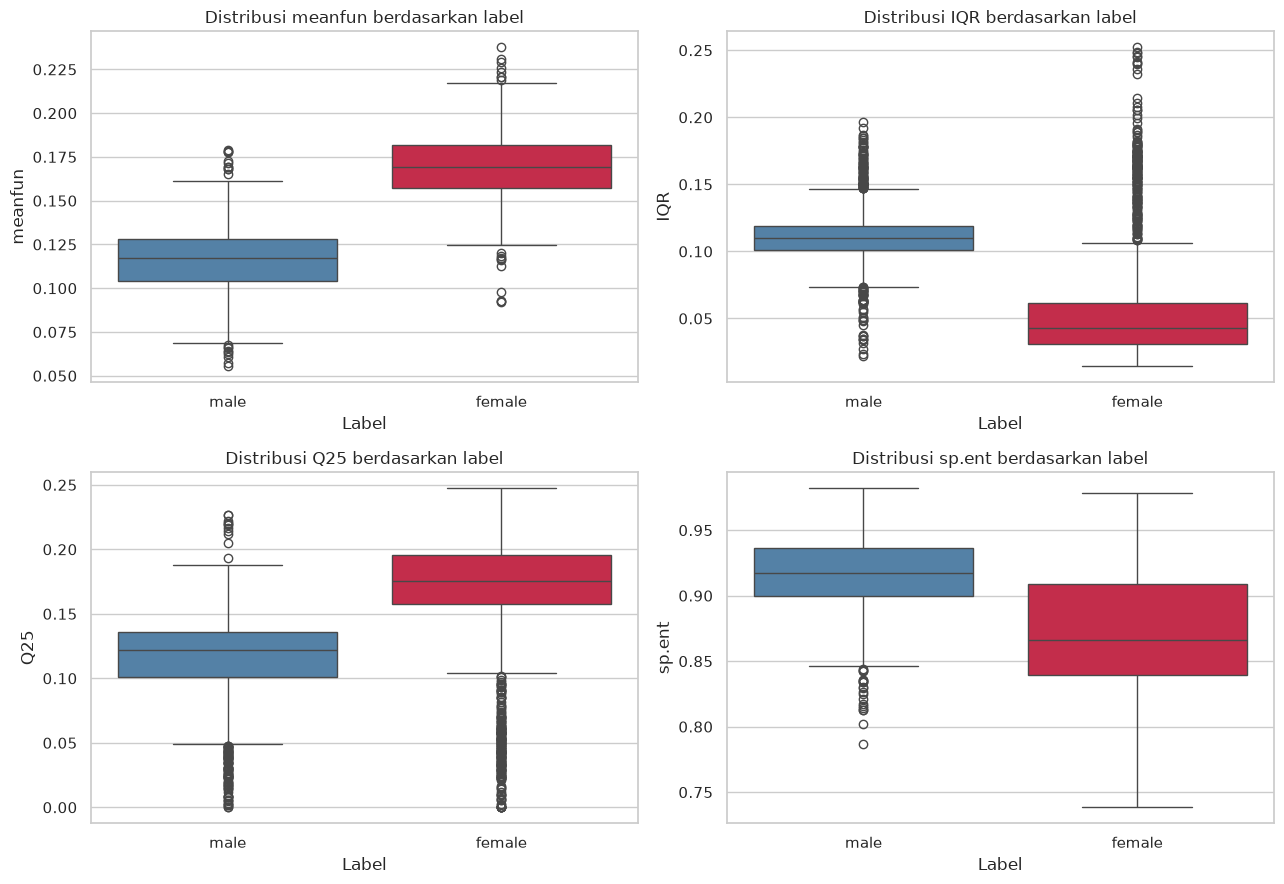

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, kolom in zip(axes.ravel(), ["meanfun", "IQR", "Q25", "sp.ent"]):
    sns.boxplot(
        data=voice,
        x="label",
        y=kolom,
        hue="label",
        palette={"male": "steelblue", "female": "crimson"},
        legend=False,
        ax=ax,
    )
    ax.set_title(f"Distribusi {kolom} berdasarkan label")
    ax.set_xlabel("Label")
    ax.set_ylabel(kolom)

plt.tight_layout()
plt.show()

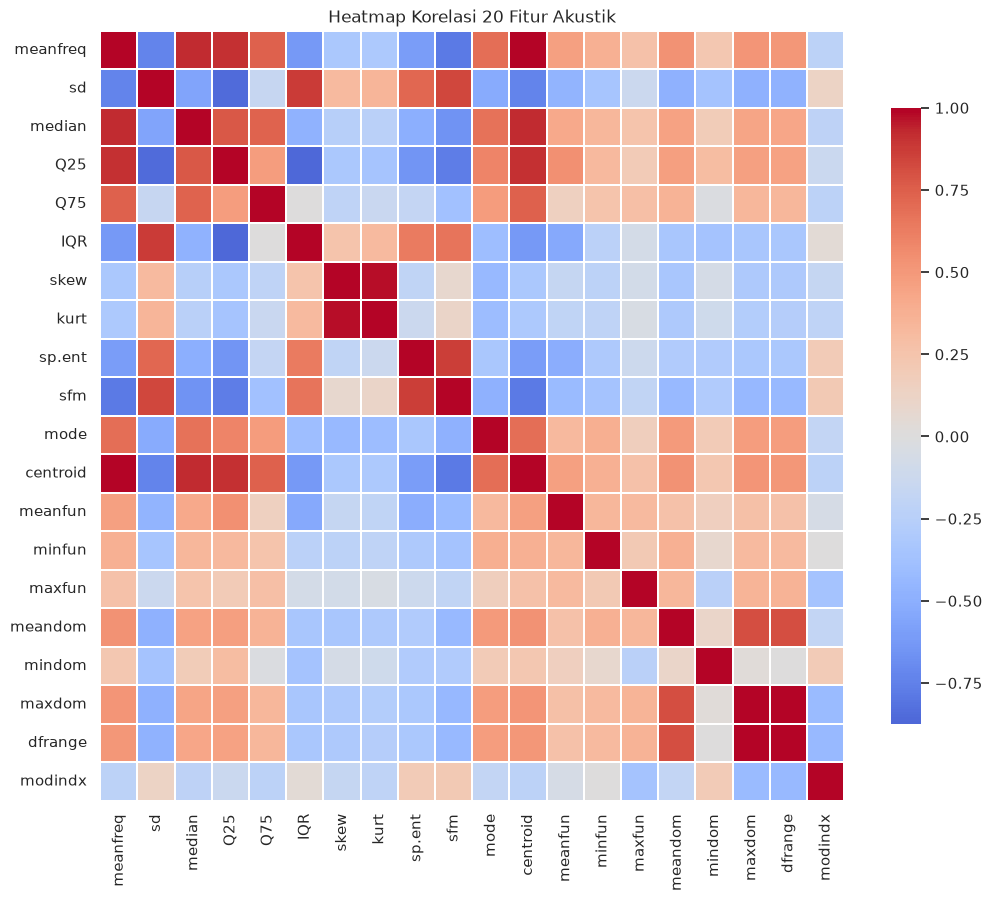

In [8]:
plt.figure(figsize=(12, 10))
sns.heatmap(
    voice.drop(columns="label").corr(),
    cmap="coolwarm",
    center=0,
    linewidths=0.3,
    cbar_kws={"shrink": 0.8},
)
plt.title("Heatmap Korelasi 20 Fitur Akustik")
plt.show()

Heatmap menunjukkan beberapa kelompok fitur yang saling berkorelasi sangat tinggi, misalnya `meanfreq` dan `centroid`. Fitur yang redundan dapat mengganggu kNN karena keduanya memberi bobot berlebih pada informasi yang sama. Oleh karena itu, seleksi fitur relevan dan tidak redundan berpotensi meningkatkan performa.

### 3. Pembagian data dan standardisasi

Data dibagi **80% latih dan 20% uji** dengan `stratify=y` agar proporsi pria/wanita seimbang. Standardisasi dilakukan **di dalam pipeline** agar scaler hanya belajar dari data latih pada setiap fold validasi silang, sehingga tidak terjadi data leakage.

In [9]:
X = voice.drop(columns="label")
y = voice["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)

print("Data latih :", X_train.shape)
print("Data uji   :", X_test.shape)
print("\nDistribusi label latih:", y_train.value_counts().to_dict())
print("Distribusi label uji  :", y_test.value_counts().to_dict())

Data latih : (2534, 20)
Data uji   : (634, 20)

Distribusi label latih: {'male': 1267, 'female': 1267}
Distribusi label uji  : {'female': 317, 'male': 317}


### 4. Baseline: semua 20 fitur

Sebelum seleksi fitur, kita cari nilai k terbaik dengan seluruh fitur menggunakan **5-fold stratified cross-validation** pada data latih. Baseline ini menjadi pembanding untuk mengetahui apakah seleksi fitur benar-benar membantu.

In [10]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
neighbors = list(range(1, 31))

baseline_cv = []
baseline_train = []

for k in neighbors:
    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier(n_neighbors=k)),
    ])
    scores = cross_val_score(
        pipeline, X_train, y_train, cv=cv, scoring="accuracy", n_jobs=-1
    )
    baseline_cv.append(scores.mean())

    pipeline.fit(X_train, y_train)
    baseline_train.append(pipeline.score(X_train, y_train))

baseline_best_k = neighbors[int(np.argmax(baseline_cv))]
print(f"k terbaik baseline: {baseline_best_k}")
print(f"CV accuracy baseline: {max(baseline_cv):.4f}")

k terbaik baseline: 3
CV accuracy baseline: 0.9740


### 5. Seleksi fitur dengan ANOVA F-score

`SelectKBest` dengan `f_classif` memberi skor pada setiap fitur berdasarkan seberapa besar perbedaan rata-rata antar kelas relatif terhadap variasi di dalam kelas. Semakin besar F-score, semakin informatif fitur tersebut untuk membedakan `male` dan `female`.

Kita tidak langsung memilih top-N secara arbitrer. Kita uji **N = 1 sampai 20** fitur terbaik menggunakan pipeline dan 5-fold CV, lalu memilih N dengan akurasi CV tertinggi. Seleksi dilakukan **di dalam pipeline** pada setiap fold, sehingga hasil CV tidak bocor oleh informasi data uji.

In [11]:
selector_all = SelectKBest(score_func=f_classif, k="all")
selector_all.fit(X_train, y_train)

skor_fitur = pd.DataFrame({
    "Fitur": X.columns,
    "F-score": selector_all.scores_,
}).sort_values("F-score", ascending=False)

skor_fitur.round(3)

,Fitur,F-score
12,meanfun,5697.874
5,IQR,1566.488
3,Q25,890.387
8,sp.ent,794.113
1,sd,750.763
9,sfm,375.207
11,centroid,324.436
0,meanfreq,324.436
2,median,218.280
16,mindom,100.409


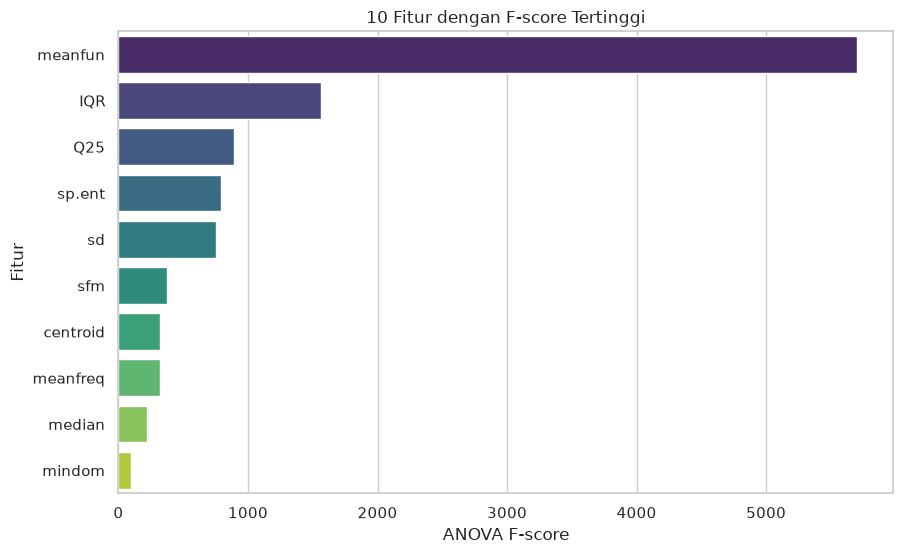

In [12]:
plt.figure(figsize=(10, 6))
sns.barplot(
    data=skor_fitur.head(10),
    x="F-score",
    y="Fitur",
    hue="Fitur",
    palette="viridis",
    legend=False,
)
plt.title("10 Fitur dengan F-score Tertinggi")
plt.xlabel("ANOVA F-score")
plt.ylabel("Fitur")
plt.show()

In [13]:
jumlah_fitur = list(range(1, X_train.shape[1] + 1))
cv_per_fitur = []

for n_fitur in jumlah_fitur:
    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("select", SelectKBest(score_func=f_classif, k=n_fitur)),
        ("knn", KNeighborsClassifier(n_neighbors=5)),
    ])
    scores = cross_val_score(
        pipeline, X_train, y_train, cv=cv, scoring="accuracy", n_jobs=-1
    )
    cv_per_fitur.append(scores.mean())

best_n_features = jumlah_fitur[int(np.argmax(cv_per_fitur))]
print(f"Jumlah fitur terbaik: {best_n_features}")
print(f"CV accuracy: {max(cv_per_fitur):.4f}")

pd.DataFrame({
    "Jumlah fitur": jumlah_fitur,
    "CV accuracy": cv_per_fitur,
}).round(4).T

Jumlah fitur terbaik: 6
CV accuracy: 0.9799


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
Jumlah fitur,1.0000,2.000,3.0000,4.0000,5.0000,6.0000,7.0000,8.0000,9.0000,10.0000,11.0000,12.0000,13.0000,14.0000,15.0000,16.0000,17.000,18.0000,19.0000,20.0000
CV accuracy,0.9408,0.968,0.9736,0.9724,0.9775,0.9799,0.9779,0.9791,0.9763,0.9787,0.9759,0.9747,0.9736,0.9708,0.9732,0.9728,0.972,0.9708,0.9712,0.9696


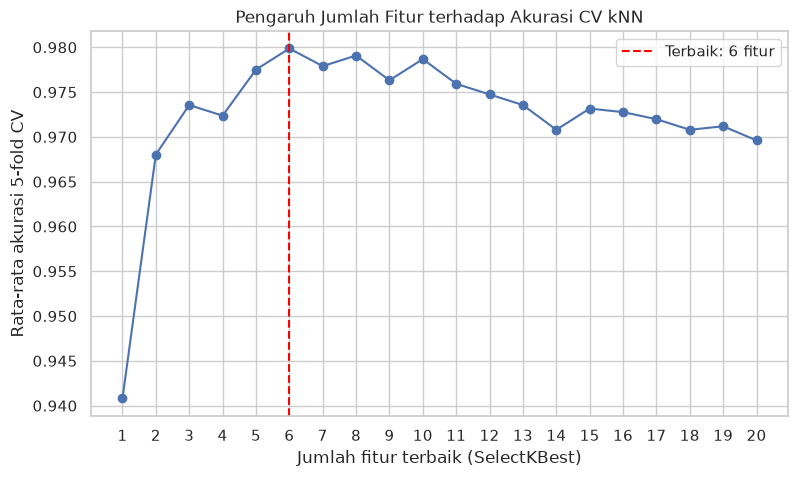

In [14]:
plt.figure(figsize=(9, 5))
plt.plot(jumlah_fitur, cv_per_fitur, marker="o")
plt.axvline(best_n_features, color="red", linestyle="--", label=f"Terbaik: {best_n_features} fitur")
plt.title("Pengaruh Jumlah Fitur terhadap Akurasi CV kNN")
plt.xlabel("Jumlah fitur terbaik (SelectKBest)")
plt.ylabel("Rata-rata akurasi 5-fold CV")
plt.xticks(jumlah_fitur)
plt.legend()
plt.show()

In [15]:
selector_best = SelectKBest(score_func=f_classif, k=best_n_features)
selector_best.fit(X_train, y_train)
selected_features = X.columns[selector_best.get_support()].tolist()

print("Fitur terpilih:")
for i, fitur in enumerate(selected_features, 1):
    f_score = skor_fitur.loc[skor_fitur["Fitur"] == fitur, "F-score"].iloc[0]
    print(f"{i}. {fitur:10s} (F = {f_score:.2f})")

Fitur terpilih:
1. sd         (F = 750.76)
2. Q25        (F = 890.39)
3. IQR        (F = 1566.49)
4. sp.ent     (F = 794.11)
5. sfm        (F = 375.21)
6. meanfun    (F = 5697.87)


**Fitur terpilih (6 fitur):** `meanfun`, `IQR`, `Q25`, `sp.ent`, `sd`, dan `sfm`.

- `meanfun` (mean fundamental frequency) adalah fitur yang paling kuat. Suara pria umumnya memiliki frekuensi fundamental lebih rendah daripada suara wanita.
- `IQR` dan `Q25` menggambarkan sebaran frekuensi bawah; keduanya membantu membedakan karakter distribusi spektral.
- `sp.ent` (spectral entropy) dan `sd` (standard deviation) menangkap variasi/kompleksitas sinyal.
- `sfm` (spectral flatness measure) membedakan sinyal tonal dan noise-like.

Fitur yang sangat berkorelasi seperti `meanfreq` dan `centroid` tidak masuk karena informasinya sudah terwakili oleh fitur lain dan dapat menduplikasi bobot jarak.

### 6. Menentukan nilai k terbaik pada fitur terpilih

Dengan 6 fitur terpilih, kita uji kembali `k = 1` sampai `30`. Grafik menampilkan akurasi data latih dan akurasi 5-fold CV. Nilai k terbaik dipilih berdasarkan **CV tertinggi**, bukan akurasi data latih.

In [16]:
selected_cv = []
selected_train = []

for k in neighbors:
    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("select", SelectKBest(score_func=f_classif, k=best_n_features)),
        ("knn", KNeighborsClassifier(n_neighbors=k)),
    ])
    scores = cross_val_score(
        pipeline, X_train, y_train, cv=cv, scoring="accuracy", n_jobs=-1
    )
    selected_cv.append(scores.mean())

    pipeline.fit(X_train, y_train)
    selected_train.append(pipeline.score(X_train, y_train))

best_k = neighbors[int(np.argmax(selected_cv))]
print(f"k terbaik: {best_k}")
print(f"CV accuracy: {max(selected_cv):.4f}")

k terbaik: 3
CV accuracy: 0.9814


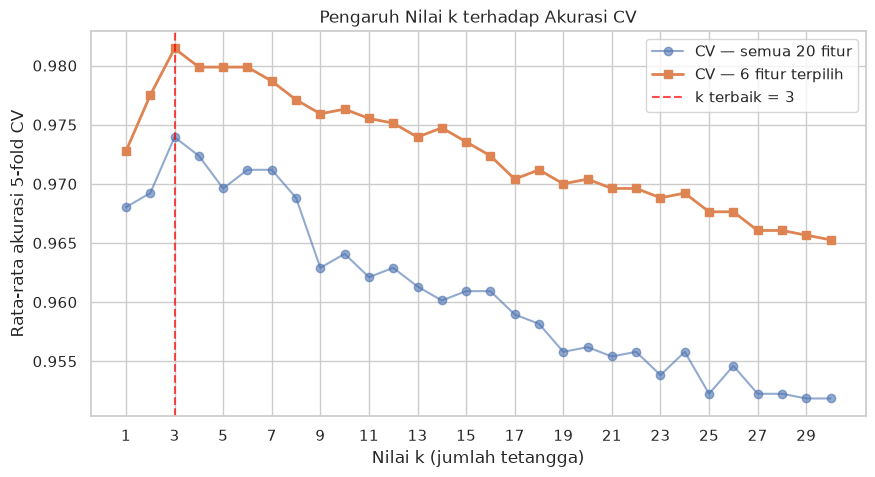

In [17]:
plt.figure(figsize=(10, 5))

plt.plot(neighbors, baseline_cv, marker="o", alpha=0.6, label="CV — semua 20 fitur")
plt.plot(neighbors, selected_cv, marker="s", linewidth=2, label=f"CV — {best_n_features} fitur terpilih")
plt.axvline(best_k, color="red", linestyle="--", alpha=0.7, label=f"k terbaik = {best_k}")

plt.title("Pengaruh Nilai k terhadap Akurasi CV")
plt.xlabel("Nilai k (jumlah tetangga)")
plt.ylabel("Rata-rata akurasi 5-fold CV")
plt.xticks(range(1, 31, 2))
plt.legend()
plt.show()

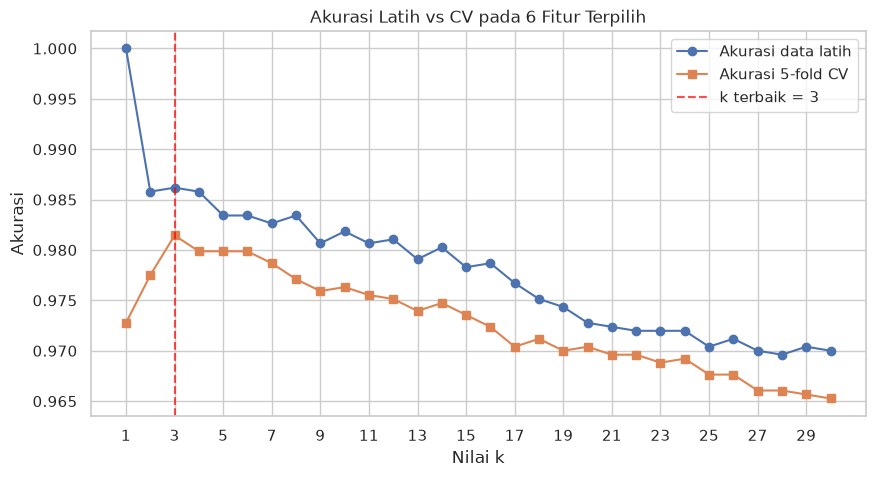

In [18]:
plt.figure(figsize=(10, 5))
plt.plot(neighbors, selected_train, marker="o", label="Akurasi data latih")
plt.plot(neighbors, selected_cv, marker="s", label="Akurasi 5-fold CV")
plt.axvline(best_k, color="red", linestyle="--", alpha=0.7, label=f"k terbaik = {best_k}")
plt.title("Akurasi Latih vs CV pada 6 Fitur Terpilih")
plt.xlabel("Nilai k")
plt.ylabel("Akurasi")
plt.xticks(range(1, 31, 2))
plt.legend()
plt.show()

**Analisis grafik k**

- Pada `k=1`, akurasi data latih mencapai 1,0 karena setiap titik memprediksi dirinya sendiri. Namun akurasi CV lebih rendah, tanda overfitting.
- Akurasi CV meningkat tajam sampai `k=3`, lalu perlahan menurun ketika k terlalu besar.
- `k=3` memberi akurasi CV sekitar **0,9814**, nilai tertinggi pada 6 fitur terpilih.
- Nilai ganjil (3) juga menghindari kemungkinan suara seri pada klasifikasi biner.
- Setelah `k=3`, kurva cenderung menurun karena batas keputusan menjadi terlalu halus dan pola lokal mulai hilang.

Jadi nilai k terbaik adalah **k = 3**.

### 7. Evaluasi model final pada data uji

Model final menggunakan pipeline:

1. `StandardScaler`
2. `SelectKBest(f_classif, k=6)`
3. `KNeighborsClassifier(n_neighbors=3)`

Pipeline di-fit pada seluruh data latih, lalu diuji pada 20% data uji yang belum pernah dilihat model.

In [19]:
model_final = Pipeline([
    ("scaler", StandardScaler()),
    ("select", SelectKBest(score_func=f_classif, k=best_n_features)),
    ("knn", KNeighborsClassifier(n_neighbors=best_k)),
])

model_final.fit(X_train, y_train)
y_pred = model_final.predict(X_test)

acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, pos_label="male")
rec = recall_score(y_test, y_pred, pos_label="male")
f1 = f1_score(y_test, y_pred, pos_label="male")

metrik_final = pd.DataFrame({
    "Metrik": ["Accuracy", "Precision (male)", "Recall (male)", "F1-score (male)"],
    "Nilai": [acc, prec, rec, f1],
})
metrik_final["Nilai"] = metrik_final["Nilai"].map(lambda v: f"{v:.4f}")
metrik_final

,Metrik,Nilai
0,Accuracy,0.9874
1,Precision (male),0.9874
2,Recall (male),0.9874
3,F1-score (male),0.9874


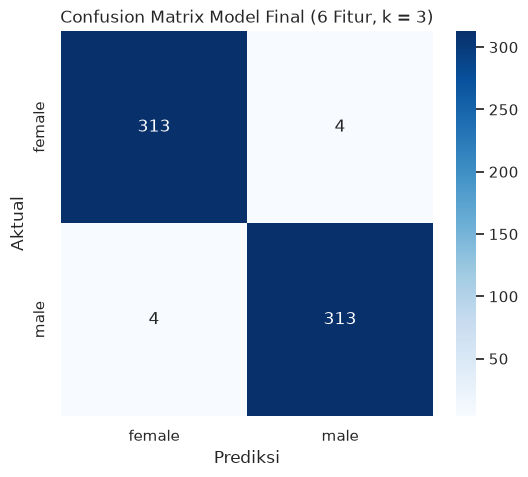

              precision    recall  f1-score   support

      female     0.9874    0.9874    0.9874       317
        male     0.9874    0.9874    0.9874       317

    accuracy                         0.9874       634
   macro avg     0.9874    0.9874    0.9874       634
weighted avg     0.9874    0.9874    0.9874       634



In [20]:
labels = ["female", "male"]
cm = confusion_matrix(y_test, y_pred, labels=labels)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels,
)
plt.title("Confusion Matrix Model Final (6 Fitur, k = 3)")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.show()

print(classification_report(y_test, y_pred, digits=4))

### 8. Perbandingan baseline dan model terpilih

Model baseline memakai semua 20 fitur dengan k terbaik hasil tuning. Model terpilih memakai 6 fitur dan k=3. Perbandingan ini menunjukkan apakah seleksi fitur memberikan manfaat nyata.

In [21]:
baseline_model = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=baseline_best_k)),
])
baseline_model.fit(X_train, y_train)
y_pred_baseline = baseline_model.predict(X_test)

perbandingan = pd.DataFrame({
    "Model": ["Baseline — 20 fitur", "Terpilih — 6 fitur"],
    "k terbaik": [baseline_best_k, best_k],
    "CV accuracy": [max(baseline_cv), max(selected_cv)],
    "Test accuracy": [
        accuracy_score(y_test, y_pred_baseline),
        accuracy_score(y_test, y_pred),
    ],
    "F1 male": [
        f1_score(y_test, y_pred_baseline, pos_label="male"),
        f1_score(y_test, y_pred, pos_label="male"),
    ],
})
perbandingan.round(4)

,Model,k terbaik,CV accuracy,Test accuracy,F1 male
0,Baseline — 20 fitur,3,0.9740,0.9763,0.9765
1,Terpilih — 6 fitur,3,0.9814,0.9874,0.9874


### 9. Analisis dan kesimpulan

**Fitur paling optimal**

Enam fitur terpilih adalah `meanfun`, `IQR`, `Q25`, `sp.ent`, `sd`, dan `sfm`. `meanfun` sangat dominan karena frekuensi fundamental suara pria dan wanita berbeda jelas. Fitur lain melengkapi informasi tentang sebaran frekuensi dan kompleksitas sinyal. Menghapus fitur yang redundan atau lemah membuat perhitungan jarak kNN lebih fokus.

**Nilai k terbaik**

`k = 3` adalah nilai terbaik berdasarkan 5-fold CV pada 6 fitur terpilih, dengan akurasi CV sekitar **0,9814**. Grafik menunjukkan:

- `k=1` overfitting (akurasi latih 1,0, CV lebih rendah).
- `k=3` mencapai puncak CV.
- k yang lebih besar menurunkan akurasi karena batas keputusan terlalu halus.

**Performa model final**

- Akurasi data uji: **0,9874**
- Precision male: **0,9874**
- Recall male: **0,9874**
- F1-score male: **0,9874**
- Confusion matrix: 313 female benar, 313 male benar, 4 female diprediksi male, dan 4 male diprediksi female.

**Pengaruh seleksi fitur**

Baseline 20 fitur dengan k=3 mencapai akurasi uji sekitar **0,9763** dan CV **0,9740**. Setelah seleksi menjadi 6 fitur, akurasi uji naik menjadi **0,9874** dan CV menjadi **0,9799**. Peningkatan memang tidak besar, tetapi konsisten: seleksi fitur mengurangi noise dan redundansi tanpa kehilangan informasi penting.

**Keterbatasan**

- Dataset berasal dari rekaman suara tertentu; performa pada mikrofon, bahasa, atau kondisi rekaman lain bisa berbeda.
- kNN tetap sensitif terhadap outlier dan perbedaan skala, meskipun standardisasi sudah dilakukan.
- Feature selection berbasis F-score mengasumsikan hubungan linear/monoton; metode lain seperti RFE atau permutation importance bisa dibandingkan.
- Satu split data uji menghasilkan 634 sampel; validasi silang membantu, tetapi evaluasi eksternal tetap diperlukan.

**Kesimpulan**

1. kNN berhasil mengklasifikasikan jenis suara dengan akurasi uji **98,74%**.
2. Fitur terbaik: `meanfun`, `IQR`, `Q25`, `sp.ent`, `sd`, dan `sfm`.
3. Nilai k terbaik adalah **3**.
4. Seleksi fitur meningkatkan akurasi uji dari sekitar **97,63%** menjadi **98,74%** dan CV dari **97,40%** menjadi **97,99%**.

### Referensi

- Modul Praktikum Pembelajaran Mesin JS09 – Klasifikasi, Politeknik Negeri Malang. https://polinema.gitbook.io/jti-modul-praktikum-pembelajaran-mesin-2025-2026/js09-klasifikasi
- `scikit-learn` – Feature selection. https://scikit-learn.org/stable/modules/feature_selection.html
- `scikit-learn` – Nearest Neighbors. https://scikit-learn.org/stable/modules/neighbors.html
- Dataset Voice Gender (voice.csv) dari modul praktikum.